# Neural networks and optimization

**Barda Soltani Moakhar and Setayesh Heydari**  
Linear Algebra | Instructor: **Maryam Ramezani**

We connect least squares, affine classification, nonlinear feature maps, and recurrent state updates. The models and gradients are in `src/laml/models.py`. Recorded results use seed 42.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "laml").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "laml").exists():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
RECOMPUTE = False

def read_result(name):
    return json.loads((ROOT / "results" / name).read_text())

def show_figure(name):
    from PIL import Image
    display(Image.open(ROOT / "results" / "figures" / name))

In [2]:
if RECOMPUTE:
    from laml.experiments import run
    run("neural")
metrics = read_result("neural_metrics.json")
display(pd.DataFrame([metrics["gas_station"]]).T.rename(columns={0:"Value"}))

,Value
training_observations,63.000000
validation_observations,21.000000
slope_seconds_per_departure,92.723113
gradient_descent_slope,92.723113
gradient_descent_learning_rate,0.005000
training_r2,0.984399
validation_r2,0.982890
validation_rmse_seconds,74.977699


## Least squares as a projection

For the zero-intercept model $y\approx xw$, minimizing $\|xw-y\|_2^2$ gives $w^*=(x^Ty)/(x^Tx)$. The residual is orthogonal to the feature vector. The first three queues train the model; the fourth checks the trend on a held-out queue.

The feature counts departures after the first observed car. The target is elapsed time after that departure, rather than an individual driver's total wait.

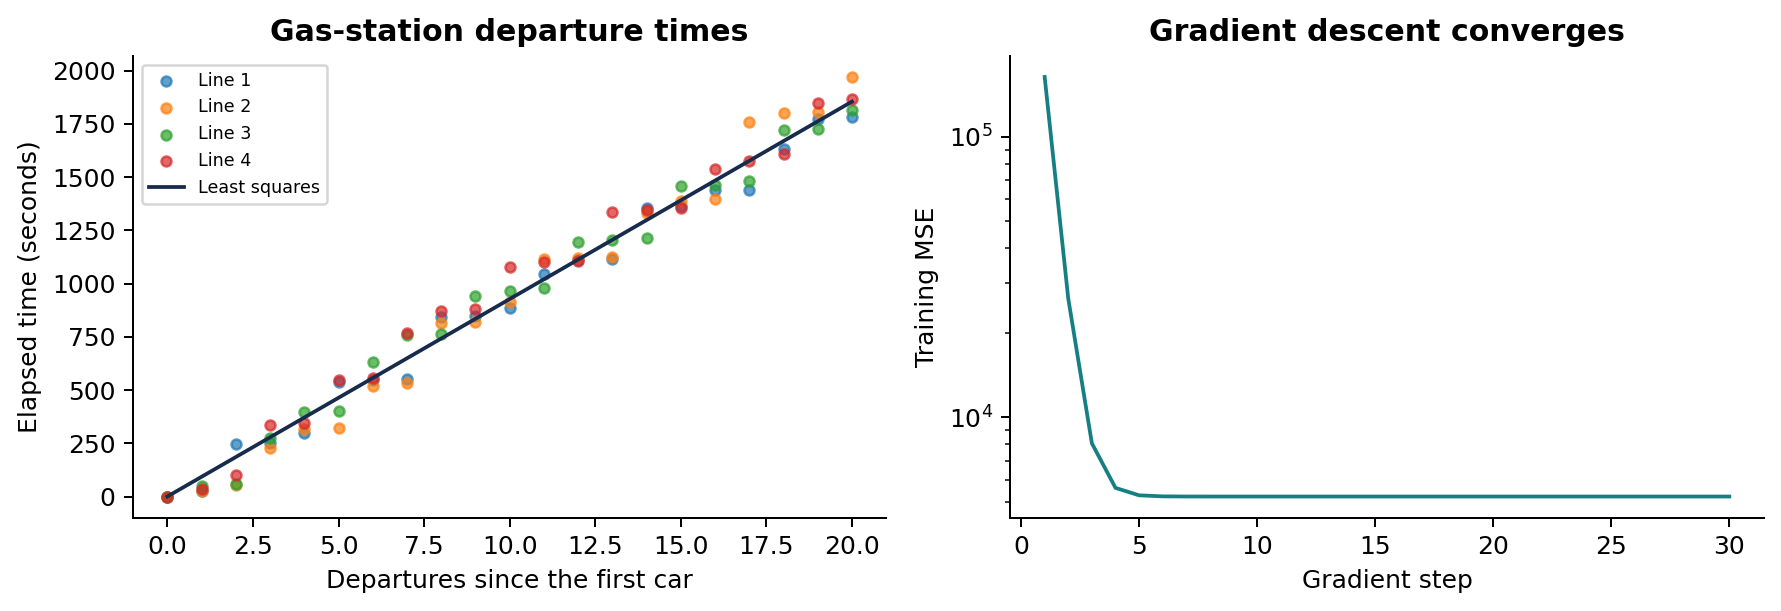

Slope: 92.723113 seconds per departure
Residual inner product: -6.912e-11


In [3]:
from laml.models import least_squares
times = pd.read_csv(ROOT / "data/raw/gas_station.csv")
seconds = times.apply(lambda column: pd.to_timedelta(column).dt.total_seconds())
seconds -= seconds.iloc[0]
x = np.tile(np.arange(len(times)), 3)
y = seconds.iloc[:, :3].to_numpy().T.ravel()
w = least_squares(x, y)
print(f"Slope: {w:.6f} seconds per departure")
print(f"Residual inner product: {x @ (w*x-y):.3e}")
show_figure("regression.png")

## Why the hidden activation matters

A binary logistic classifier has boundary $w^Tx+b=0$. It cannot separate an inner circle from an outer ring. A ReLU layer combines affine regions and can represent a bounded region.

Without the hidden activation, $(XW_1+b_1)W_2+b_2=X(W_1W_2)+(b_1W_2+b_2)$, so the model reduces to a single affine map before the final sigmoid.

,Value
small_binary_training_accuracy,1.000000
circles_logistic_test_accuracy,0.506667
circles_mlp_test_accuracy,1.000000
blobs_softmax_test_accuracy,0.966667
circles_train,350.000000
circles_test,150.000000
mlp_hidden_units,16.000000
mlp_epochs,5000.000000


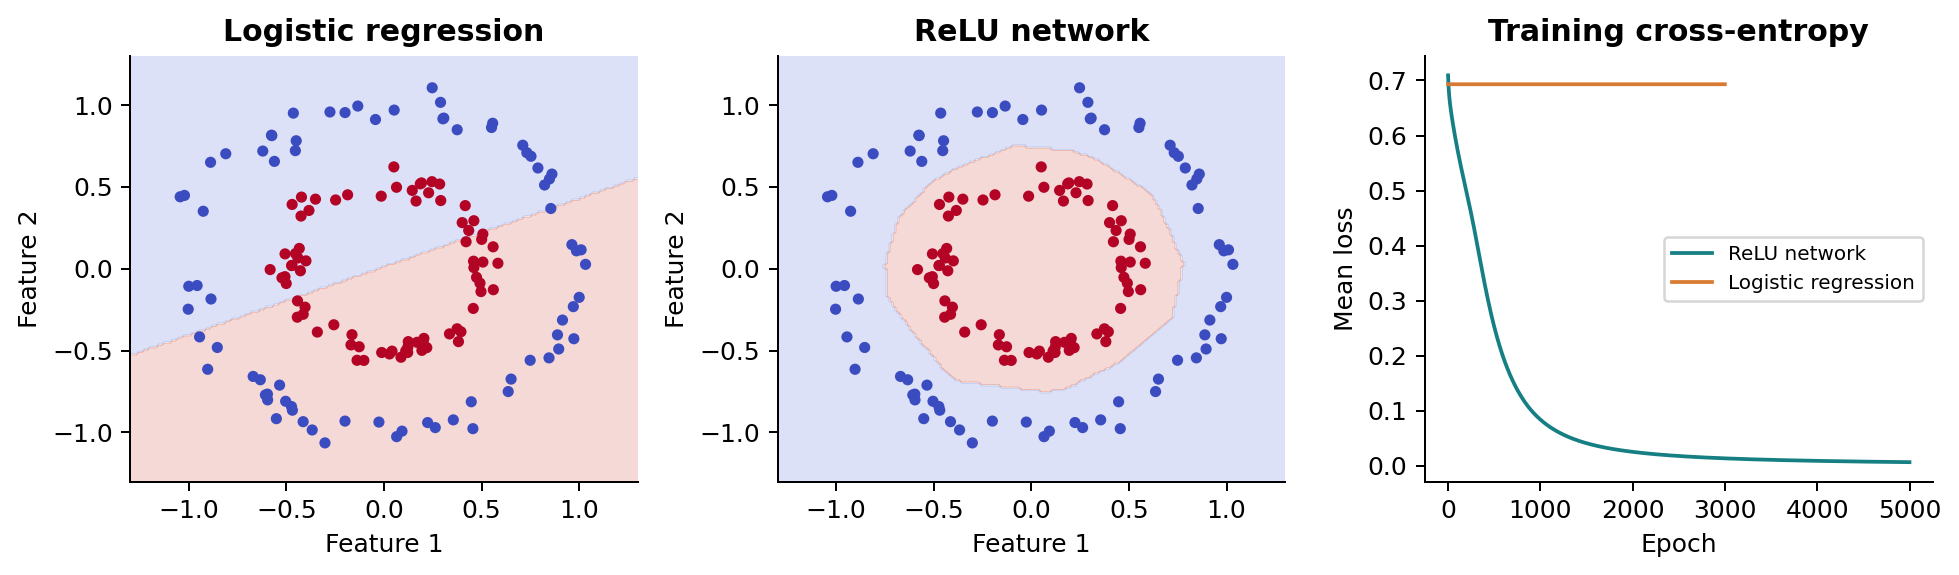

In [4]:
display(pd.DataFrame([metrics["classification"]]).T.rename(columns={0:"Value"}))
show_figure("classification.png")

## A complete backward pass

For mean binary cross-entropy, the output-logit derivative is $(P-y)/n$. The hidden derivative multiplies the upstream derivative by the ReLU mask. The source below is the implementation used in training; numerical tests check it against central finite differences.

In [5]:
import inspect
from laml.models import MLP
print(inspect.getsource(MLP.loss_grad))

    def loss_grad(self, x, y):
        p = self.params
        z1 = x @ p['w1'] + p['b1']
        a1 = np.maximum(z1, 0)
        z2 = a1 @ p['w2'] + p['b2']
        y = np.asarray(y).reshape(-1, 1)
        dz2 = (expit(z2) - y) / len(x)
        dz1 = (dz2 @ p['w2'].T) * (z1 > 0)
        return binary_loss(z2, y), {
            'w1': x.T @ dz1, 'b1': dz1.sum(axis=0),
            'w2': a1.T @ dz2, 'b2': dz2.sum(axis=0),
        }



## Character RNN

The model updates $h_t=\tanh(W_xx_t+W_hh_{t-1}+b_h)$ and predicts the next character with a softmax. Backpropagation through time accumulates gradients for the same weights across 32 positions. Independent random windows start with zero state.

The short included corpus keeps the experiment self-contained. The held-out loss and generated sample show the limits of training a language model on only a few thousand characters.

,Value
corpus,Project demo corpus
characters,3668
vocabulary,47
training_characters,2934
heldout_characters,734
hidden_size,48
sequence_length,32
steps,2000
training_nll,1.600444
heldout_nll,2.372239


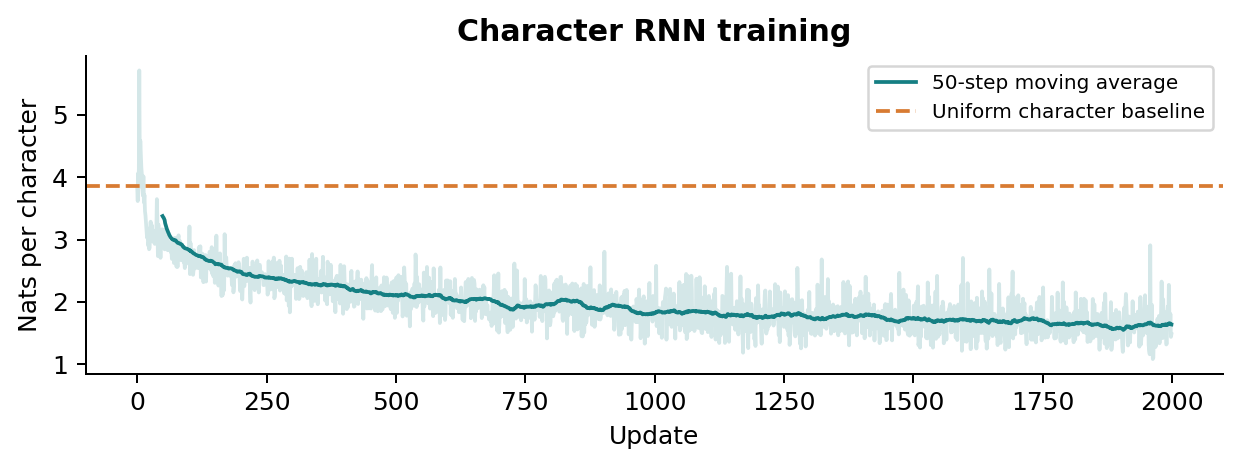

Character RNN sample | demo corpus | temperature 0.8 | seed 123

The netwerteat pfrased nea hetrrins. The deithe Leo k delligithe n aptent maling Learent shers. The bels ans rating on enton. Leo kepedtr w mparabith a lmatimatrde. Lectile mation wing biemsins. Sea chidel aity on the siuld westhe traterbition a racills wers ont ghe next.
At vectirn card thes the the shanged tho ntation a sur slaragits. They ceecill milared the neared dall st ond ouich weld the str



In [6]:
display(pd.DataFrame([metrics["rnn"]]).T.rename(columns={0:"Value"}))
show_figure("rnn_training.png")
print((ROOT / "results/generated_text.txt").read_text())

## Interpretation

High circle accuracy reflects an easy synthetic geometric task. The character RNN learns local patterns but produces malformed words. The full report gives the learning-rate condition for scalar MSE and compares the computational cost of normal equations and gradient descent.